# RehaPiano – rovnováha síl rúk: rytmický test vs. EXACT_FORCE, vek a ochorenie

**Zadanie:** *Vyhodnotiť rovnováhu síl rúk aj pre rytmický test, porovnať s exact force, analýzu robiť aj po rozdelení
na vekové kategórie, odlíšiť vplyv veku a ochorenia.*

**Dáta:** 138 osôb (90 zdravých, 48 pacientov), každá má rytmický test (RHYTHM) aj EXACT_FORCE.
- **EXACT_FORCE** – osoba drží všetkými prstami rovnomernú silu (4 pokusy po 16 s). Rovnováhu rúk sme vyhodnotili v 3. týždni.
- **RHYTHM** – osoba rytmicky stláča a uvoľňuje oboma rukami (4 pokusy po 31 s), zdraví asi 2,5-krát za sekundu, pacienti pomalšie.

**Postup:**
1. ako merať rovnováhu rúk v rytmickom teste,
2. rovnováha v rytmickom teste a počet slabo používaných rúk,
3. porovnanie s EXACT_FORCE,
4. vekové kategórie,
5. vplyv veku vs. vplyv ochorenia.

Autor analýzy: M. Kuznietsov. Kód: `src/rehapiano/rhythm/presses.py`, `src/rehapiano/rhythm/hand_balance.py`, skripty
`scripts/build_rhythm.py` a `scripts/run_rhythm_hand_balance.py` (tabuľky v `outputs/rhythm/` a `outputs/rhythm/hand_balance/`).
Načítanie a predspracovanie dát je zo spoločného balíka `src/rehapiano/common`; EXACT_FORCE hodnoty sú z 3. týždňa
(`outputs/exact_force/stats/hand_activity.csv`). Celý projekt sa prepočíta príkazom `python scripts/run_all.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

# ROOT = repository root (package src/rehapiano, data/, outputs/)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "rehapiano").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.common.config import AGE_CATEGORY_LABELS, PARTICIPANT_LABELS_CSV
from rehapiano.common.io.metadata import resolve_project_path
from rehapiano.common.preprocessing.pipeline import load_measurement_data
from rehapiano.rhythm import hand_balance as hb
from rehapiano.rhythm.config import HAND_BALANCE_OUTPUT_DIR, RHYTHM_CROP_END_S, RHYTHM_CROP_START_S, RHYTHM_OUTPUT_DIR
from rehapiano.rhythm.presses import detect_presses, hand_forces

FIG = Path.cwd() / "figures" / "rovnovaha_ruk"; FIG.mkdir(parents=True, exist_ok=True)
T = {path.stem: pd.read_csv(path) for path in sorted(HAND_BALANCE_OUTPUT_DIR.glob("*.csv"))}
T["rhythm_by_attempt"] = pd.read_csv(RHYTHM_OUTPUT_DIR / "rhythm_by_attempt.csv")
people = T["balance_by_person"]
people["age_category"] = pd.Categorical(people["age_category"], AGE_CATEGORY_LABELS, ordered=True)
attempts = T["rhythm_by_attempt"]
THR = dict(zip(T["weak_hand_thresholds"]["test"], T["weak_hand_thresholds"]["threshold"]))

GROUP_COLORS = {"control": "#2a78d6", "patient": "#eb6834"}
HAND_COLORS = {"left": "#2a78d6", "right": "#eb6834"}
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})
SK_GROUP = {"control": "Zdraví", "patient": "Pacienti"}
SK_HAND = {"left": "ľavá", "right": "pravá"}
GROUPS = ["control", "patient"]
N = people.groupby("group").size()


def fmt(value, digits=2):
    # Slovak decimal comma
    return f"{value:.{digits}f}".replace(".", ",")


def pval(p):
    return "p < 0,001" if p < 0.001 else f"p = {fmt(p, 3)}"


def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150); plt.show()

## 1. Ako merať rovnováhu rúk v rytmickom teste

V EXACT_FORCE je sila takmer stála, preto stačí **priemerná sila** ruky. V rytmickom teste sila stále stúpa a klesá –
priemer závisí aj od toho, ako dlho osoba medzi stlačeniami odpočíva. Preto meriame **samotné stlačenia**:

1. **sila ruky** = priemer piatich snímačov ruky (rovnako ako v EXACT_FORCE), úsek 2–30 s, 100 Hz;
2. **stlačenia** = vrcholy súčtu síl oboch rúk (obe ruky stláčajú naraz); stlačenie trvá od minima pred vrcholom
   po minimum za ním;
3. **amplitúda stlačenia ruky** = maximum − minimum sily ruky počas stlačenia, medián cez všetky stlačenia pokusu;
4. **rovnováha** = amplitúda slabšej ruky / amplitúda silnejšej ruky (1 = obe rovnako, 0 = jedna ruka nestláča);
   za osobu: medián cez 4 pokusy, priemer cez vyšetrenia.

Časy stlačení, ktoré zapisuje hra (`press_offset`, `release_offset`), **nepoužívame**: v niektorých záznamoch ležia na
vrcholoch sily, v iných na minimách (korelácia so silou od −0,55 do +0,70 na 30 náhodných záznamoch). Stlačenia sa preto
hľadajú priamo v signáli. Všetkých 692 pokusov malo aspoň 5 stlačení. Ruky takmer vždy stláčajú naraz;
striedavo (najprv jedna, potom druhá) len v ~1–2 % pokusov.

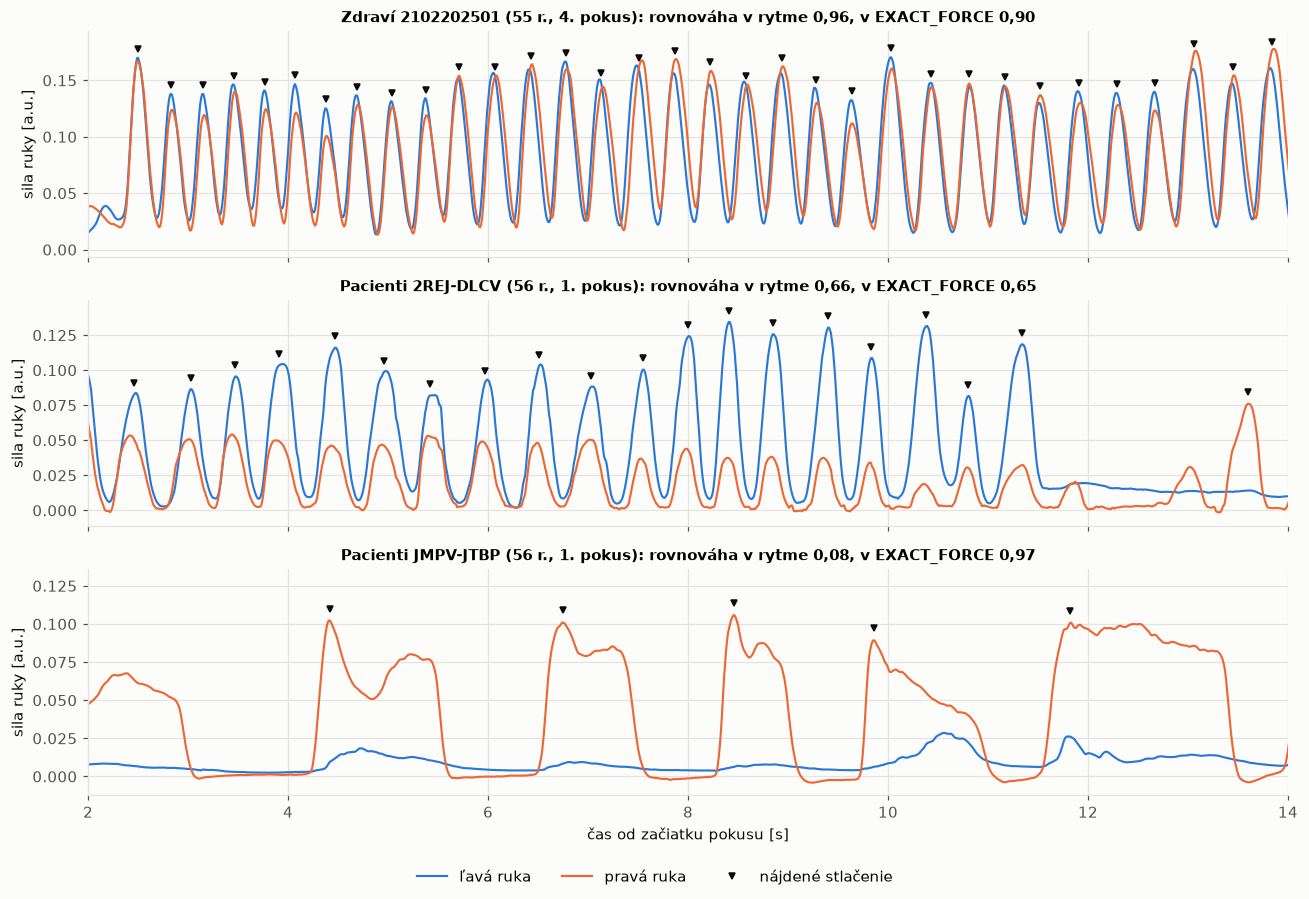

In [2]:
def show_attempt(ax, patient_id, attempt=1, xlim=(2, 14)):
    row = attempts.loc[(attempts["patient_id"] == patient_id) & (attempts["attempt"] == attempt)].iloc[0]
    data = load_measurement_data(resolve_project_path(row["file_path"]), RHYTHM_CROP_START_S, RHYTHM_CROP_END_S)
    data = data.loc[(data["attempt"] == attempt) & (data["segment"] == 1)]
    force = hand_forces(data); time = data["time_s"].to_numpy()
    presses = detect_presses(force["left"] + force["right"])
    for hand in ("left", "right"):
        ax.plot(time, force[hand], color=HAND_COLORS[hand], lw=1.4, label=f"{SK_HAND[hand]} ruka")
    peaks = [p for _, p, _ in presses]
    top = np.maximum(force["left"], force["right"])
    ax.plot(time[peaks], top[peaks] + 0.008, "v", color=TEXT, ms=4, label="nájdené stlačenie")
    person = people.set_index("patient_id").loc[patient_id]
    ax.set_title(f"{SK_GROUP[person['group']]} {patient_id} ({person['age']:.0f} r., {attempt}. pokus): rovnováha v rytme "
                 f"{fmt(person['rhythm_ratio'])}, v EXACT_FORCE {fmt(person['exact_force_ratio'])}", fontsize=10)
    ax.set_xlim(*xlim); ax.set_ylabel("sila ruky [a.u.]")

EXAMPLES = [("2102202501", 4), ("2REJ-DLCV", 1), ("JMPV-JTBP", 1)]
fig, axes = plt.subplots(len(EXAMPLES), 1, figsize=(12, 8.2), sharex=True)
for ax, (pid, attempt) in zip(axes, EXAMPLES):
    show_attempt(ax, pid, attempt)
axes[-1].set_xlabel("čas od začiatku pokusu [s]")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(FIG / "01_rytmicky_test_priklady.png", dpi=150); plt.show()

Hore zdravá osoba – obe ruky stláčajú rovnako. V strede pacient s ľavou rukou mierne slabšou. Dole pacient JMPV-JTBP:
v EXACT_FORCE drží obe ruky takmer rovnako (0,97), ale v rytme stláča **iba pravou rukou** – ľavá ruka sa takmer nehýbe.
Rytmický test teda meria niečo iné ako EXACT_FORCE: nie či ruka **drží silu**, ale či ju vie **opakovane rýchlo stláčať
a uvoľňovať**.

### Tempo stláčania

Stlačenia sú rýchle – zdraví stláčajú a uvoľňujú v priemere viac ako dvakrát za sekundu. Nie je to chyba výpočtu:
počet stlačení sme overili aj na surových dátach s časovými značkami zariadenia (~1000 vzoriek/s, pokus trvá 31 s).
Hra zrejme vyžaduje stláčať čo najrýchlejšie – protokol výskumu uvádza ako výsledok testu frekvenciu stláčania.
Tempo = počet nájdených stlačení / dĺžka úseku (28 s), za osobu medián cez pokusy a priemer cez vyšetrenia.

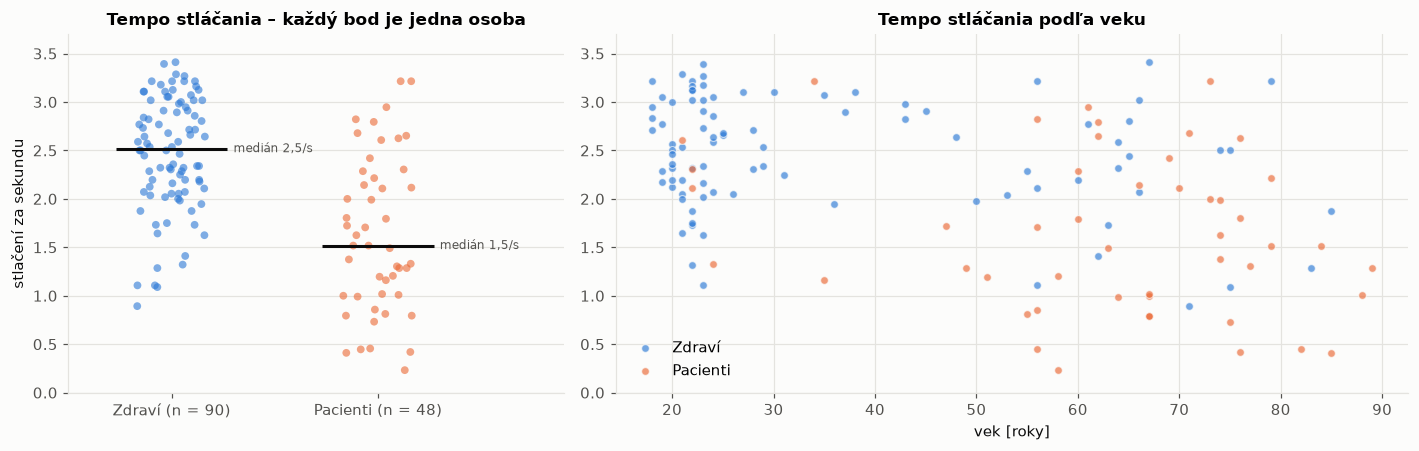

size          median         
group            Zdraví Pacienti Zdraví Pacienti
veková kategória                                
10–19                 8        0   2.80      NaN
20–29                48        4   2.52     2.21
30–39                 6        2   2.98     2.19
40–49                 4        2   2.87     1.50
50–59                 6        8   2.07     1.03
60–69                11       13   2.45     1.79
70–79                 5       14   2.50     1.90
80–89                 2        5   1.58     1.01

Zdraví vs. pacienti: p < 0,001; zdraví – tempo a vek: Spearmanovo ρ = -0,13, p = 0,238


In [3]:
rate = people[["patient_id", "group", "age", "age_category", "press_rate_hz"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
rng = np.random.default_rng(2)
for i, group in enumerate(GROUPS):
    v = rate.loc[rate["group"] == group, "press_rate_hz"]
    axes[0].scatter(i + rng.uniform(-0.17, 0.17, len(v)), v, s=26, color=GROUP_COLORS[group], alpha=0.6, edgecolor="none")
    axes[0].hlines(v.median(), i - 0.27, i + 0.27, color=TEXT, lw=2)
    axes[0].text(i + 0.3, v.median(), f"medián {fmt(v.median(), 1)}/s", va="center", fontsize=8, color=MUTED)
axes[0].set_xticks([0, 1], [f"{SK_GROUP[g]} (n = {N[g]})" for g in GROUPS]); axes[0].set_xlim(-0.5, 1.9)
axes[0].set_ylabel("stlačení za sekundu"); axes[0].set_title("Tempo stláčania – každý bod je jedna osoba")
axes[0].grid(axis="x", visible=False)
for group in GROUPS:
    frame = rate.loc[rate["group"] == group]
    axes[1].scatter(frame["age"], frame["press_rate_hz"], s=26, color=GROUP_COLORS[group], alpha=0.65,
                    edgecolor=SURFACE, linewidth=0.8, label=SK_GROUP[group])
axes[1].set_xlabel("vek [roky]"); axes[1].set_title("Tempo stláčania podľa veku"); axes[1].legend(loc="lower left")
for ax in axes:
    ax.set_ylim(0, 3.7)
save(fig, "02_tempo_stlacani")

p_rate = stats.mannwhitneyu(rate.loc[rate.group == "control", "press_rate_hz"], rate.loc[rate.group == "patient", "press_rate_hz"]).pvalue
rho_age_c, p_age_c = stats.spearmanr(rate.loc[rate.group == "control", "age"], rate.loc[rate.group == "control", "press_rate_hz"])
display(rate.groupby(["age_category", "group"], observed=False)["press_rate_hz"].agg(["size", "median"]).round(2)
        .unstack("group").rename(columns=SK_GROUP).rename_axis("veková kategória"))
print(f"Zdraví vs. pacienti: {pval(p_rate)}; zdraví – tempo a vek: Spearmanovo ρ = {fmt(rho_age_c)}, {pval(p_age_c)}")

Pacienti stláčajú pomalšie (medián ~1,5 vs. ~2,5 stlačenia za sekundu) a ich tempo je veľmi rozdielne – od pár
stlačení za pokus (napr. JMPV-JTBP) až po tempo zdravých. U zdravých tempo s vekom neklesá (ρ = −0,13, p = 0,24),
a pacienti sú pomalší vo všetkých vekových kategóriách – pomalšie tempo teda nie je dôsledkom veku. Rozdiel v tempe môže čiastočne pochádzať aj z inej verzie
hry pre pacientov. V časti 5 preto overujeme, že horšia rovnováha rúk pacientov nie je len dôsledkom pomalšieho tempa.

## 2. Rovnováha síl v rytmickom teste

Prah slabo používanej ruky je určený rovnako ako v 3. týždni: **2,5 % kvantil zdravých** – nižšiu rovnováhu má len
2,5 % zdravých osôb.

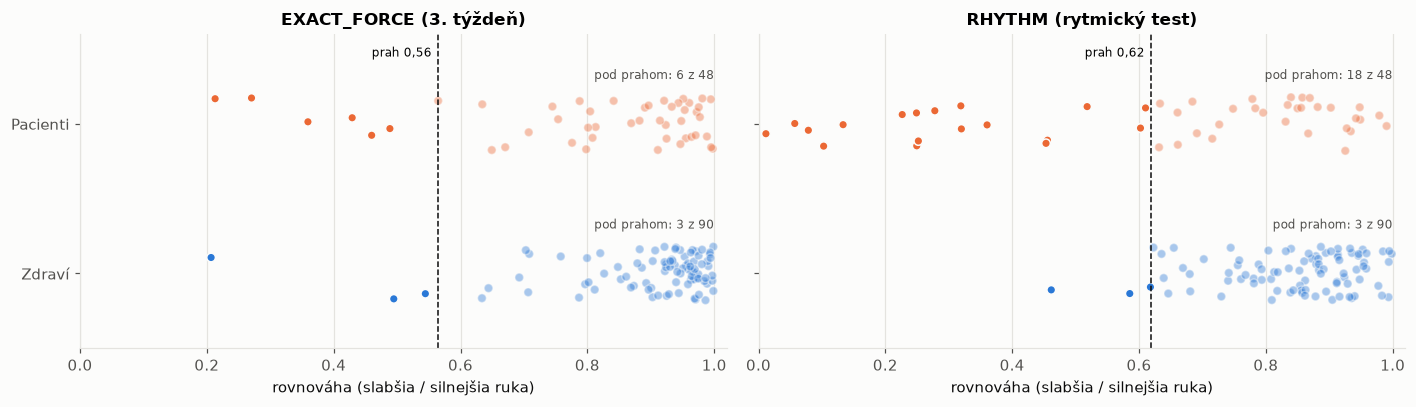

,osob,rytmus_median,rytmus_Q1,exact_force_median,slaba_ruka_rytmus,slaba_ruka_exact_force,tempo_stlaceni_Hz
group,,,,,,,
Zdraví,90,0.87,0.79,0.94,3,3,2.52
Pacienti,48,0.70,0.35,0.89,18,6,1.52


Rovnováha v rytme, zdraví vs. pacienti (Mann-Whitney): p < 0,001


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
rng = np.random.default_rng(0)
for ax, test, title in [(axes[0], "exact_force", "EXACT_FORCE (3. týždeň)"), (axes[1], "rhythm", "RHYTHM (rytmický test)")]:
    thr = THR[hb.TESTS[test]]
    for row, group in enumerate(GROUPS):
        frame = people.loc[people["group"] == group]
        below = frame[f"{test}_ratio"] < thr
        ax.scatter(frame[f"{test}_ratio"], row + rng.uniform(-0.18, 0.18, len(frame)), s=32, color=GROUP_COLORS[group],
                   alpha=np.where(below, 1.0, 0.4), edgecolor=SURFACE, linewidth=1)
        ax.text(1.0, row + 0.3, f"pod prahom: {int(below.sum())} z {len(frame)}", ha="right", fontsize=8, color=MUTED)
    ax.axvline(thr, color=TEXT, lw=1, ls="--")
    ax.text(thr - 0.01, 1.45, f"prah {fmt(thr)}", ha="right", fontsize=8)
    ax.set_xlim(0, 1.02); ax.set_title(title); ax.grid(axis="y", visible=False)
    ax.set_xlabel("rovnováha (slabšia / silnejšia ruka)")
axes[0].set_yticks([0, 1], [SK_GROUP[g] for g in GROUPS]); axes[0].set_ylim(-0.5, 1.6)
save(fig, "03_rovnovaha_oba_testy")

summary = people.groupby("group").agg(
    osob=("patient_id", "size"),
    rytmus_median=("rhythm_ratio", "median"), rytmus_Q1=("rhythm_ratio", lambda v: v.quantile(0.25)),
    exact_force_median=("exact_force_ratio", "median"),
    slaba_ruka_rytmus=("weak_rhythm", "sum"), slaba_ruka_exact_force=("weak_exact_force", "sum"),
    tempo_stlaceni_Hz=("press_rate_hz", "median")).rename(index=SK_GROUP)
display(summary.round(2))
p_rh = stats.mannwhitneyu(people.loc[people.group == "control", "rhythm_ratio"],
                          people.loc[people.group == "patient", "rhythm_ratio"]).pvalue
print(f"Rovnováha v rytme, zdraví vs. pacienti (Mann-Whitney): {pval(p_rh)}")

In [5]:
weak_rh = people.loc[(people["group"] == "patient") & people["weak_rhythm"].astype(bool)].sort_values("rhythm_ratio")
display(weak_rh[["patient_id", "age", "gender", "rhythm_weaker_hand", "rhythm_ratio", "exact_force_ratio", "weak_exact_force"]]
        .assign(rhythm_weaker_hand=lambda t: t["rhythm_weaker_hand"].map(SK_HAND),
                weak_exact_force=lambda t: t["weak_exact_force"].map({True: "áno", False: "nie"}))
        .rename(columns={"patient_id": "pacient", "age": "vek", "gender": "pohlavie", "rhythm_weaker_hand": "slabšia ruka (rytmus)",
                         "rhythm_ratio": "rovnováha – rytmus", "exact_force_ratio": "rovnováha – EXACT_FORCE",
                         "weak_exact_force": "slabá aj v EXACT_FORCE"}).round(2).reset_index(drop=True))
n_rh, n_ef = int(people.loc[people.group == "patient", "weak_rhythm"].sum()), int(people.loc[people.group == "patient", "weak_exact_force"].sum())
display(Markdown(f'''
**Záver 2:** v rytmickom teste má slabo používanú ruku **{n_rh} zo {N["patient"]} pacientov**
({fmt(100 * n_rh / N["patient"], 0)} %), v EXACT_FORCE len {n_ef}. U zdravých je to
{int(people.loc[people.group == "control", "weak_rhythm"].sum())} z {N["control"]} (zodpovedá prahu 2,5 %).
Pacienti majú v rytme výrazne nižšiu rovnováhu (medián {fmt(summary.loc["Pacienti", "rytmus_median"])} vs.
{fmt(summary.loc["Zdraví", "rytmus_median"])}, {pval(p_rh)}). Úplne nečinnú ruku nemá nikto, ale u 0IKB-27Y1
a 3OUS-NI9J slabšia ruka v rytme takmer nestláča (rovnováha pod 0,06).
'''))

,pacient,vek,pohlavie,slabšia ruka (rytmus),rovnováha – rytmus,rovnováha – EXACT_FORCE,slabá aj v EXACT_FORCE
0,0IKB-27Y1,75,female,ľavá,0.01,0.21,áno
1,3OUS-NI9J,82,female,ľavá,0.06,0.27,áno
2,JMPV-JTBP,56,male,ľavá,0.08,0.97,nie
3,OQHZ-N4AV,60,male,pravá,0.10,0.67,nie
4,NUYV-81KG,88,female,ľavá,0.13,0.56,nie
5,0HXU-5CYJ,67,male,pravá,0.23,0.84,nie
6,XT2X-WLNW,67,male,pravá,0.25,0.49,áno
7,6JRZ-KPE6,51,male,ľavá,0.25,0.78,nie
8,ALVB-UZKR,35,male,ľavá,0.25,0.89,nie
9,V6TD-3R18,24,male,ľavá,0.28,0.98,nie



**Záver 2:** v rytmickom teste má slabo používanú ruku **18 zo 48 pacientov**
(38 %), v EXACT_FORCE len 6. U zdravých je to
3 z 90 (zodpovedá prahu 2,5 %).
Pacienti majú v rytme výrazne nižšiu rovnováhu (medián 0,70 vs.
0,87, p < 0,001). Úplne nečinnú ruku nemá nikto, ale u 0IKB-27Y1
a 3OUS-NI9J slabšia ruka v rytme takmer nestláča (rovnováha pod 0,06).


## 3. Porovnanie s EXACT_FORCE

Každý bod je jedna osoba: vodorovne rovnováha v EXACT_FORCE, zvisle v rytmickom teste. Prerušované čiary sú prahy oboch
testov. Ak by testy merali to isté, body by ležali pozdĺž uhlopriečky.

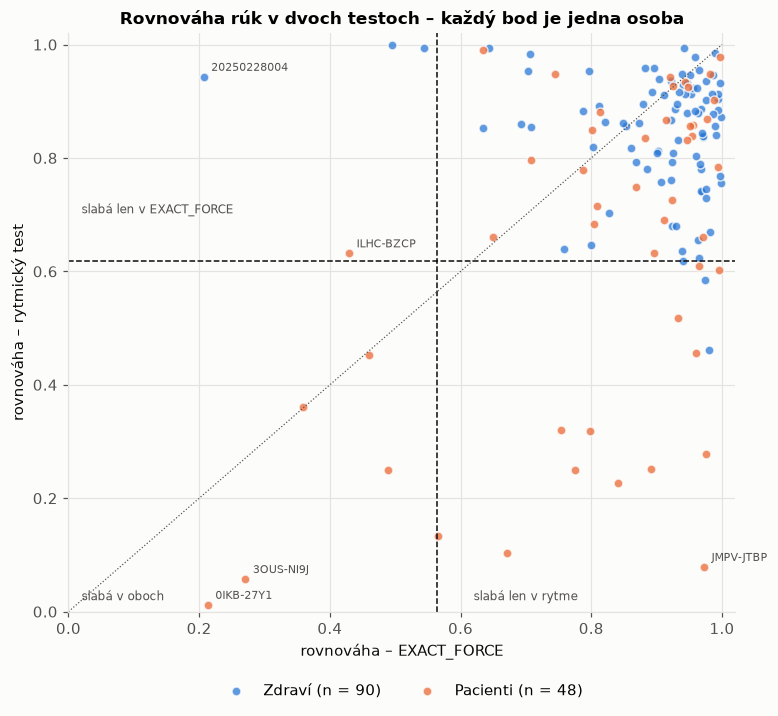

,Spearmanovo ρ,p,slabá v oboch,len EXACT_FORCE,len rytmus,ani v jednom
skupina,,,,,,
Zdraví,-0.15,0.168,0,3,3,84
Pacienti,0.40,0.005,5,1,13,29


Ak je ruka slabá aspoň v jednom teste, je to v oboch testoch tá istá ruka u 88 % osôb.


In [6]:
fig, ax = plt.subplots(figsize=(7.2, 6.6))
for group in GROUPS:
    frame = people.loc[people["group"] == group]
    ax.scatter(frame["exact_force_ratio"], frame["rhythm_ratio"], s=34, color=GROUP_COLORS[group], alpha=0.75,
               edgecolor=SURFACE, linewidth=1, label=f"{SK_GROUP[group]} (n = {len(frame)})")
ax.axvline(THR["EXACT_FORCE"], color=TEXT, lw=1, ls="--"); ax.axhline(THR["RHYTHM"], color=TEXT, lw=1, ls="--")
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls=":")
for pid in ["0IKB-27Y1", "3OUS-NI9J", "JMPV-JTBP", "ILHC-BZCP", "20250228004"]:
    r = people.set_index("patient_id").loc[pid]
    ax.annotate(pid, (r["exact_force_ratio"], r["rhythm_ratio"]), xytext=(5, 4), textcoords="offset points", fontsize=7.5, color=MUTED)
ax.text(0.02, 0.02, "slabá v oboch", fontsize=8, color=MUTED); ax.text(0.62, 0.02, "slabá len v rytme", fontsize=8, color=MUTED)
ax.text(0.02, 0.72, "slabá len v EXACT_FORCE", fontsize=8, color=MUTED, va="top")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.set_xlabel("rovnováha – EXACT_FORCE"); ax.set_ylabel("rovnováha – rytmický test")
ax.set_title("Rovnováha rúk v dvoch testoch – každý bod je jedna osoba")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
save(fig, "04_exact_force_vs_rytmus")

ag = T["test_agreement"].iloc[0]
rows = []
for group in GROUPS:
    frame = people.loc[people["group"] == group]
    rho, p = stats.spearmanr(frame["exact_force_ratio"], frame["rhythm_ratio"])
    a, b = frame["weak_exact_force"].astype(bool), frame["weak_rhythm"].astype(bool)
    rows.append({"skupina": SK_GROUP[group], "Spearmanovo ρ": round(rho, 2), "p": round(p, 3),
                 "slabá v oboch": int((a & b).sum()), "len EXACT_FORCE": int((a & ~b).sum()),
                 "len rytmus": int((~a & b).sum()), "ani v jednom": int((~a & ~b).sum())})
display(pd.DataFrame(rows).set_index("skupina"))
print(f"Ak je ruka slabá aspoň v jednom teste, je to v oboch testoch tá istá ruka u "
      f"{fmt(100 * ag['same_weaker_hand_if_flagged'], 0)} % osôb.")

**Opakovateľnosť rytmického testu:** 35 pacientov má dve vyšetrenia s odstupom niekoľkých dní. Ak by výsledok bol len
náhodný šum, prvé a druhé vyšetrenie by spolu nesúviseli.

In [7]:
valid = attempts.loc[attempts["status"] == "valid"]
per_exam = valid.groupby(["patient_id", "measurement_id", "timestamp", "hand"])["press_amplitude"].median().unstack("hand")
per_exam["ratio"] = per_exam.min(axis=1) / per_exam.max(axis=1)
per_exam = per_exam.reset_index().sort_values(["patient_id", "timestamp"])
pairs = per_exam.groupby("patient_id").filter(lambda d: len(d) == 2).groupby("patient_id")["ratio"].agg(["first", "last"])
rho_rep, p_rep = stats.spearmanr(pairs["first"], pairs["last"])
print(f"Rytmus, 1. vs. 2. vyšetrenie pacienta (n = {len(pairs)}): Spearmanovo ρ = {fmt(rho_rep)}, {pval(p_rep)}")

Rytmus, 1. vs. 2. vyšetrenie pacienta (n = 35): Spearmanovo ρ = 0,76, p < 0,001


In [8]:
rho_c = rows[0]["Spearmanovo ρ"]; rho_p = rows[1]["Spearmanovo ρ"]
display(Markdown(f'''
**Záver 3:**
- Testy sa **zhodujú len čiastočne**. U pacientov spolu súvisia (ρ = {fmt(rho_p)}), u zdravých nie (ρ = {fmt(rho_c)}) –
  zdraví majú v oboch testoch rovnováhu blízko 1 a rozdiely sú len malé náhodné odchýlky.
- Slabú ruku v **oboch** testoch má {int(ag["weak_both"])} osôb (0IKB-27Y1, 3OUS-NI9J, EJIT-XSEZ, W6JM-R0SG, XT2X-WLNW),
  **len v rytme** {int(ag["weak_only_rhythm"])} a **len v EXACT_FORCE** {int(ag["weak_only_exact_force"])}.
  Ak je ruka slabá, takmer vždy ide o **tú istú ruku** ({fmt(100 * ag["same_weaker_hand_if_flagged"], 0)} %).
- Rytmický test je **citlivejší**: nájde všetkých pacientov slabých v EXACT_FORCE okrem ILHC-BZCP a navyše ďalších
  13 pacientov. Rytmické stláčanie je pre postihnutú ruku náročnejšie ako držanie sily (príklad JMPV-JTBP v časti 1).
- Rytmický test je **opakovateľný**: rovnováha pacienta v prvom a druhom vyšetrení silno súvisí (ρ = {fmt(rho_rep)}).
'''))


**Záver 3:**
- Testy sa **zhodujú len čiastočne**. U pacientov spolu súvisia (ρ = 0,40), u zdravých nie (ρ = -0,15) –
  zdraví majú v oboch testoch rovnováhu blízko 1 a rozdiely sú len malé náhodné odchýlky.
- Slabú ruku v **oboch** testoch má 5 osôb (0IKB-27Y1, 3OUS-NI9J, EJIT-XSEZ, W6JM-R0SG, XT2X-WLNW),
  **len v rytme** 16 a **len v EXACT_FORCE** 4.
  Ak je ruka slabá, takmer vždy ide o **tú istú ruku** (88 %).
- Rytmický test je **citlivejší**: nájde všetkých pacientov slabých v EXACT_FORCE okrem ILHC-BZCP a navyše ďalších
  13 pacientov. Rytmické stláčanie je pre postihnutú ruku náročnejšie ako držanie sily (príklad JMPV-JTBP v časti 1).
- Rytmický test je **opakovateľný**: rovnováha pacienta v prvom a druhom vyšetrení silno súvisí (ρ = 0,76).


## 4. Vekové kategórie (po 10 rokoch)

Ľudí delíme do **10-ročných vekových skupín** ako v histograme veku z 3. týždňa. Pozor na malé počty: zdravých nad 50 rokov
je len 24 (6 / 11 / 5 / 2) a pacientov pod 50 rokov len 8. Skupiny s menej ako 3 osobami ukazujeme, ale netestujeme.

group,Pacienti,Zdraví
veková kategória,,
10–19,0,8
20–29,4,48
30–39,2,6
40–49,2,4
50–59,8,6
60–69,13,11
70–79,14,5
80–89,5,2


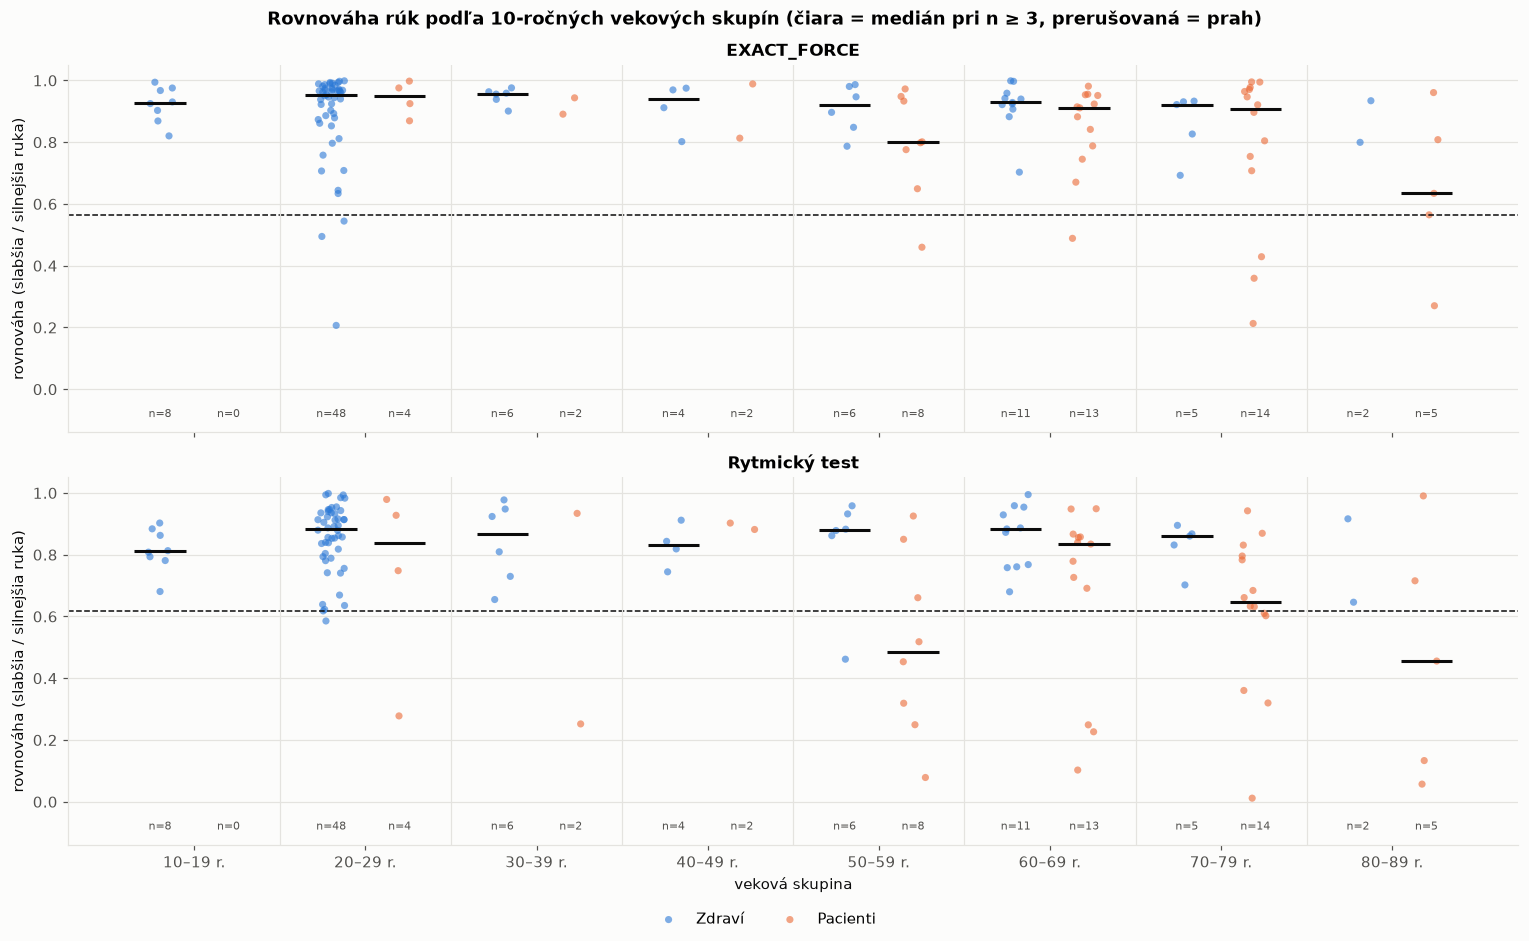

Medián rovnováhy a počet slabo používaných rúk v každej vekovej skupine:


test,EXACT_FORCE,rytmus,EXACT_FORCE,rytmus
group,Zdraví,Zdraví,Pacienti,Pacienti
veková skupina,,,,
10–19,"0,93 (slabá 0 z 8)","0,81 (slabá 0 z 8)",–,–
20–29,"0,95 (slabá 3 z 48)","0,88 (slabá 2 z 48)","0,95 (slabá 0 z 4)","0,84 (slabá 1 z 4)"
30–39,"0,96 (slabá 0 z 6)","0,87 (slabá 0 z 6)","0,92 (slabá 0 z 2)","0,59 (slabá 1 z 2)"
40–49,"0,94 (slabá 0 z 4)","0,83 (slabá 0 z 4)","0,90 (slabá 0 z 2)","0,89 (slabá 0 z 2)"
50–59,"0,92 (slabá 0 z 6)","0,88 (slabá 1 z 6)","0,80 (slabá 1 z 8)","0,49 (slabá 5 z 8)"
60–69,"0,93 (slabá 0 z 11)","0,88 (slabá 0 z 11)","0,91 (slabá 1 z 13)","0,83 (slabá 3 z 13)"
70–79,"0,92 (slabá 0 z 5)","0,86 (slabá 0 z 5)","0,91 (slabá 3 z 14)","0,65 (slabá 5 z 14)"
80–89,"0,87 (slabá 0 z 2)","0,78 (slabá 0 z 2)","0,63 (slabá 1 z 5)","0,46 (slabá 3 z 5)"


Zdraví, EXACT_FORCE: rozdiel medzi 7 vekovými skupinami (Kruskal-Wallis) p = 0,823
Zdraví, RHYTHM: rozdiel medzi 7 vekovými skupinami (Kruskal-Wallis) p = 0,730


In [9]:
display(pd.crosstab(people["age_category"], people["group"].map(SK_GROUP)).rename_axis("veková kategória"))
cat = T["balance_by_age_category"]
fig, axes = plt.subplots(2, 1, figsize=(14, 8.6), sharex=True)
rng = np.random.default_rng(1)
for ax, test, title in [(axes[0], "exact_force", "EXACT_FORCE"), (axes[1], "rhythm", "Rytmický test")]:
    for i, category in enumerate(AGE_CATEGORY_LABELS):
        for offset, group in zip((-0.2, 0.2), GROUPS):
            v = people.loc[(people["age_category"] == category) & (people["group"] == group), f"{test}_ratio"].dropna()
            ax.scatter(i + offset + rng.uniform(-0.08, 0.08, len(v)), v, s=22, color=GROUP_COLORS[group], alpha=0.6,
                       edgecolor="none", label=SK_GROUP[group] if i == 0 else None)
            if len(v) >= 3:
                ax.hlines(v.median(), i + offset - 0.15, i + offset + 0.15, color=TEXT, lw=2)
            ax.text(i + offset, -0.09, f"n={len(v)}", ha="center", fontsize=7.5, color=MUTED)
    ax.axhline(THR[hb.TESTS[test]], color=TEXT, lw=1, ls="--")
    ax.set_title(title); ax.grid(axis="x", visible=False); ax.set_ylim(-0.14, 1.05)
    ax.set_ylabel("rovnováha (slabšia / silnejšia ruka)")
    for i in range(1, len(AGE_CATEGORY_LABELS)):
        ax.axvline(i - 0.5, color=GRID, lw=0.8)
axes[1].set_xticks(range(len(AGE_CATEGORY_LABELS)), [f"{c} r." for c in AGE_CATEGORY_LABELS])
axes[1].set_xlabel("veková skupina")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.suptitle("Rovnováha rúk podľa 10-ročných vekových skupín (čiara = medián pri n ≥ 3, prerušovaná = prah)",
             fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG / "05_vekove_kategorie.png", dpi=150); plt.show()

show = cat.assign(group=cat["group"].map(SK_GROUP), test=cat["test"].map({"EXACT_FORCE": "EXACT_FORCE", "RHYTHM": "rytmus"}))
show["text"] = np.where(show["n_people"] > 0,
                        show["median_ratio"].map(lambda v: fmt(v)) + "  (slabá " + show["n_weak"].astype(str) + " z "
                        + show["n_people"].astype(str) + ")", "–")
print("Medián rovnováhy a počet slabo používaných rúk v každej vekovej skupine:")
display(show.pivot_table(index="age_category", columns=["test", "group"], values="text", aggfunc="first", sort=False)
        .reindex(AGE_CATEGORY_LABELS).rename_axis("veková skupina"))

# Mení sa rovnováha zdravých medzi 10-ročnými skupinami? (Kruskal-Wallis, skupiny s n >= 3)
for test in hb.TESTS:
    controls = people.loc[people["group"] == "control"]
    groups = [g[f"{test}_ratio"].dropna() for _, g in controls.groupby("age_category", observed=True) if len(g) >= 3]
    h, p_kw = stats.kruskal(*groups)
    print(f"Zdraví, {hb.TESTS[test]}: rozdiel medzi {len(groups)} vekovými skupinami (Kruskal-Wallis) {pval(p_kw)}")

## 5. Vplyv veku vs. vplyv ochorenia

Problém: pacienti sú **starší** (medián 66,5 vs. 24 rokov). Ak majú horšiu rovnováhu rúk, môže to byť vekom aj ochorením.
Oba vplyvy oddelíme tromi spôsobmi:

| Otázka | Metóda |
|---|---|
| a) Mení sa rovnováha s vekom **sama osebe**? | iba zdraví: korelácia veku a rovnováhy, mladší (< 50) vs. starší (≥ 50) |
| b) Líšia sa pacienti od zdravých **rovnakého veku**? | pacienti vs. zdraví v každej 10-ročnej skupine zvlášť a spolu ≥ 50 rokov (Mann-Whitney, Holmova korekcia) |
| c) Koľko vysvetľuje vek a koľko ochorenie **naraz**? | lineárny model: rovnováha = b₀ + b_vek · (vek / 10) + b_ochorenie · pacient |

### a) Vek u zdravých

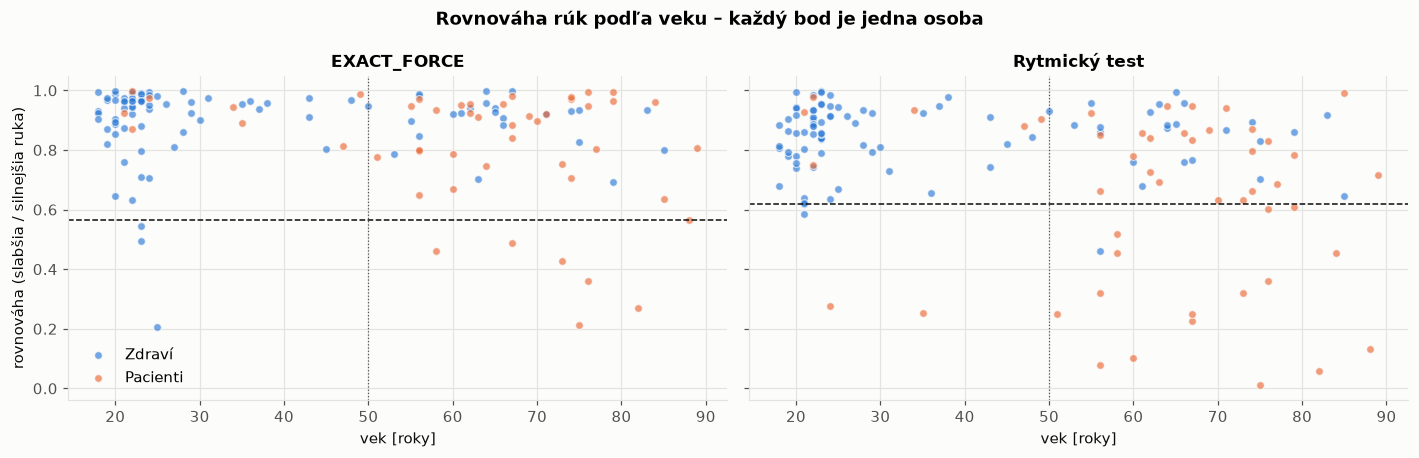

,"Spearmanovo ρ (vek, rovnováha)",p,medián < 50 rokov,medián ≥ 50 rokov,p (Mann-Whitney)
test,,,,,
EXACT_FORCE,-0.09,0.38,0.95,0.93,0.21
RHYTHM,0.07,0.50,0.86,0.88,0.99


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, test, title in [(axes[0], "exact_force", "EXACT_FORCE"), (axes[1], "rhythm", "Rytmický test")]:
    for group in GROUPS:
        frame = people.loc[people["group"] == group]
        ax.scatter(frame["age"], frame[f"{test}_ratio"], s=26, color=GROUP_COLORS[group], alpha=0.65,
                   edgecolor=SURFACE, linewidth=0.8, label=SK_GROUP[group])
    ax.axhline(THR[hb.TESTS[test]], color=TEXT, lw=1, ls="--")
    ax.axvline(50, color=MUTED, lw=0.8, ls=":")
    ax.set_title(title); ax.set_xlabel("vek [roky]")
axes[0].set_ylabel("rovnováha (slabšia / silnejšia ruka)")
axes[0].legend(loc="lower left")
fig.suptitle("Rovnováha rúk podľa veku – každý bod je jedna osoba", fontweight="bold")
save(fig, "06_vek_a_rovnovaha")

age = T["age_effect_controls"]
display(pd.DataFrame({
    "test": age["test"],
    "Spearmanovo ρ (vek, rovnováha)": age["spearman_rho_age"].round(2),
    "p": age["spearman_p"].round(2),
    "medián < 50 rokov": age["young_vs_old_median_a"].round(2),
    "medián ≥ 50 rokov": age["young_vs_old_median_b"].round(2),
    "p (Mann-Whitney)": age["young_vs_old_p"].round(2)}).set_index("test"))

U zdravých sa rovnováha rúk s vekom **nemení** – v žiadnom teste (korelácia blízko 0, mladší a starší majú takmer rovnaký
medián). Vek sám osebe teda rovnováhu rúk nezhoršuje.

### b) Pacienti vs. zdraví rovnakého veku

In [11]:
dis = T["disease_effect_by_age"]
display(pd.DataFrame({
    "test": dis["test"], "veková kategória": dis["age_category"],
    "zdraví (n)": dis["n_controls"], "pacienti (n)": dis["n_patients"],
    "medián zdraví": dis["median_controls"].round(2), "medián pacienti": dis["median_patients"].round(2),
    "p": dis["p"].map(lambda p: f"{p:.4f}"), "p (Holm)": dis["p_holm"].map(lambda p: f"{p:.4f}")}))

,test,veková kategória,zdraví (n),pacienti (n),medián zdraví,medián pacienti,p,p (Holm)
0,EXACT_FORCE,20–29,48,4,0.95,0.95,0.5176,1.0000
1,EXACT_FORCE,50–59,6,8,0.92,0.80,0.1812,0.8219
2,EXACT_FORCE,60–69,11,13,0.93,0.91,0.1644,0.8219
3,EXACT_FORCE,70–79,5,14,0.92,0.91,0.8932,1.0000
4,EXACT_FORCE,≥ 50 spolu,24,40,0.93,0.86,0.0868,0.6075
5,RHYTHM,20–29,48,4,0.88,0.84,0.7280,1.0000
6,RHYTHM,50–59,6,8,0.88,0.49,0.0293,0.2637
7,RHYTHM,60–69,11,13,0.88,0.83,0.0929,0.6075
8,RHYTHM,70–79,5,14,0.86,0.65,0.0339,0.2711
9,RHYTHM,≥ 50 spolu,24,40,0.88,0.67,0.0002,0.0022


Testujú sa len skupiny, kde majú zdraví aj pacienti aspoň 3 osoby: 20–29, 50–59, 60–69 a 70–79 rokov (plus všetci ≥ 50 spolu).
- **20–29 rokov:** 4 pacienti sa od zdravých nelíšia.
- **Rytmický test:** v každej skupine od 50 rokov majú pacienti nižší medián ako zdraví (50–59: 0,49 vs. 0,88;
  60–69: 0,83 vs. 0,88; 70–79: 0,65 vs. 0,86). Samostatné skupiny sú však malé (5–14 osôb), takže po Holmovej korekcii
  na 10 testov nie sú významné. Keď spojíme všetkých ≥ 50 rokov, rozdiel je **jednoznačný** (0,67 vs. 0,88,
  p = 0,0002, po korekcii 0,002).
- **EXACT_FORCE:** rozdiely sú menšie a nevýznamné v žiadnej skupine (≥ 50 rokov: 0,86 vs. 0,93, p = 0,09).

### c) Vek a ochorenie naraz (lineárny model)

In [12]:
model = T["age_disease_model"]
terms = {"intercept": "b₀ (zdravý, vek 0)", "age_per_10_years": "vek: zmena za 10 rokov", "patient": "ochorenie: pacient − zdravý"}
display(pd.DataFrame({
    "test": model["test"], "člen": model["term"].map(terms), "koeficient": model["coefficient"].round(3),
    "95 % IS": "[" + model["ci_low"].round(3).astype(str) + "; " + model["ci_high"].round(3).astype(str) + "]",
    "p": model["p"].map(lambda p: f"{p:.4f}")}).set_index(["test", "člen"]))

koeficient           95 % IS       p
test        člen                                                             
EXACT_FORCE b₀ (zdravý, vek 0)                0.934    [0.879; 0.989]  0.0000
            vek: zmena za 10 rokov           -0.010   [-0.022; 0.002]  0.0873
            ochorenie: pacient − zdravý      -0.059  [-0.114; -0.004]  0.0352
RHYTHM      b₀ (zdravý, vek 0)                0.875     [0.809; 0.94]  0.0000
            vek: zmena za 10 rokov           -0.008   [-0.026; 0.009]  0.3522
            ochorenie: pacient − zdravý      -0.199    [-0.3; -0.098]  0.0002

Model odhaduje vplyv veku **pri rovnakom zdravotnom stave** a vplyv ochorenia **pri rovnakom veku** (štandardné chyby
HC3, nevyžadujú normalitu rezíduí):
- **vek:** −0,01 za 10 rokov v oboch testoch – zanedbateľné a nevýznamné;
- **ochorenie:** v rytme −0,20 (pacient má o 0,2 nižšiu rovnováhu ako zdravý rovnakého veku, p < 0,001),
  v EXACT_FORCE −0,06 (p = 0,04).

### Kontroly
1. **Tempo stláčania.** Pacienti hrali rytmickú hru s iným nastavením (iné `step_id`) a stláčali pomalšie
   (1,5 vs. 2,5 stlačenia za sekundu). Ak tempo pridáme do modelu, alebo porovnáme len osoby s podobným tempom
   (1,5–3,5 Hz), rozdiel pacientov zostáva.
2. **Zdraví bez ťažkostí.** Podľa dotazníka (2. týždeň, M. Holovcyk – `data/participant_labels.csv`) 11 zdravých uviedlo nejaké
   ochorenie a u 3 je odpoveď nejasná. Bez týchto 14 (zostáva 76 zdravých) sú výsledky rytmického testu rovnaké.
3. **Obdobie merania.** Zdraví z TUKE (2025) a z 9. 9. 2026 majú v rytme rovnakú rovnováhu.
4. **Iná miera bez hľadania stlačení.** Rozsah sily ruky (95. − 5. percentil počas pokusu) dáva takmer rovnaké
   výsledky – nezávisí teda od toho, ako presne sa stlačenia nájdu.

In [13]:
X = np.column_stack([np.ones(len(people)), people["age"] / 10, (people["group"] == "patient").astype(float),
                     people["press_rate_hz"]])
m_rate = hb.ols(people["rhythm_ratio"], X, ["b0", "vek/10", "pacient", "tempo [Hz]"]).set_index("term")
similar = people.loc[people["press_rate_hz"].between(1.5, 3.5)]
p_similar = stats.mannwhitneyu(similar.loc[similar.group == "control", "rhythm_ratio"],
                               similar.loc[similar.group == "patient", "rhythm_ratio"]).pvalue
print(f"1) Model s tempom: ochorenie {fmt(m_rate.loc['pacient', 'coefficient'], 3)} ({pval(m_rate.loc['pacient', 'p'])}), "
      f"tempo {fmt(m_rate.loc['tempo [Hz]', 'coefficient'], 3)} ({pval(m_rate.loc['tempo [Hz]', 'p'])}); "
      f"tempo 1,5–3,5 Hz: zdraví {similar.group.eq('control').sum()}, pacienti {similar.group.eq('patient').sum()}, "
      f"medián {fmt(similar.loc[similar.group == 'control', 'rhythm_ratio'].median())} vs. "
      f"{fmt(similar.loc[similar.group == 'patient', 'rhythm_ratio'].median())}, {pval(p_similar)}")

labels = pd.read_csv(PARTICIPANT_LABELS_CSV)
screened = people.loc[people["patient_id"].isin(labels.loc[labels["eligible_comparison"], "patient_id"])].copy()
thr_s = {t: hb.weak_threshold(screened, f"{t}_ratio") for t in hb.TESTS}
screened = hb.add_weak_flags(screened, thr_s)
m_s = hb.age_disease_model(screened).set_index(["test", "term"])
d_s = hb.disease_effect_by_age(screened).set_index(["test", "age_category"])
print(f"2) 76 zdravých bez ťažkostí: prah rytmu {fmt(thr_s['rhythm'])}, slabá ruka v rytme u "
      f"{int(screened.loc[screened.group == 'patient', 'weak_rhythm'].sum())} pacientov; ochorenie v rytme "
      f"{fmt(m_s.loc[('RHYTHM', 'patient'), 'coefficient'], 3)} ({pval(m_s.loc[('RHYTHM', 'patient'), 'p'])}), "
      f"vek {fmt(m_s.loc[('RHYTHM', 'age_per_10_years'), 'coefficient'], 3)} ({pval(m_s.loc[('RHYTHM', 'age_per_10_years'), 'p'])}); "
      f"≥ 50 rokov {pval(d_s.loc[('RHYTHM', '≥ 50 spolu'), 'p'])}")
print(f"   EXACT_FORCE bez nich: ochorenie {fmt(m_s.loc[('EXACT_FORCE', 'patient'), 'coefficient'], 3)} "
      f"({pval(m_s.loc[('EXACT_FORCE', 'patient'), 'p'])}), vek {fmt(m_s.loc[('EXACT_FORCE', 'age_per_10_years'), 'coefficient'], 3)} "
      f"({pval(m_s.loc[('EXACT_FORCE', 'age_per_10_years'), 'p'])})")

controls = people.loc[people["group"] == "control"].assign(
    obdobie=lambda t: np.where(t["patient_id"].astype(str).str.startswith("9926"), "9_9_2026",
                               np.where(t["age"] >= 50, "TUKE ≥ 50", "TUKE < 50")))
print("3) Rovnováha v rytme u zdravých podľa obdobia (medián):",
      controls.groupby("obdobie")["rhythm_ratio"].median().round(2).to_dict())
rho_range, _ = stats.spearmanr(people["rhythm_ratio"], people["rhythm_range_ratio"])
thr_range = hb.weak_threshold(people, "rhythm_range_ratio")
weak_range = people["rhythm_range_ratio"] < thr_range
p_range = stats.mannwhitneyu(people.loc[(people.group == "control") & (people.age >= 50), "rhythm_range_ratio"],
                             people.loc[(people.group == "patient") & (people.age >= 50), "rhythm_range_ratio"]).pvalue
print(f"4) Rozsah sily: ρ s amplitúdou stlačení = {fmt(rho_range)}; prah {fmt(thr_range)}; slabá ruka u "
      f"{int((weak_range & (people.group == 'patient')).sum())} pacientov a {int((weak_range & (people.group == 'control')).sum())} zdravých; "
      f"≥ 50 rokov pacienti vs. zdraví {pval(p_range)}")

1) Model s tempom: ochorenie -0,166 (p < 0,001), tempo 0,053 (p = 0,088); tempo 1,5–3,5 Hz: zdraví 83, pacienti 25, medián 0,86 vs. 0,78, p = 0,003
2) 76 zdravých bez ťažkostí: prah rytmu 0,64, slabá ruka v rytme u 20 pacientov; ochorenie v rytme -0,204 (p < 0,001), vek -0,010 (p = 0,331); ≥ 50 rokov p < 0,001
   EXACT_FORCE bez nich: ochorenie -0,043 (p = 0,123), vek -0,015 (p = 0,020)
3) Rovnováha v rytme u zdravých podľa obdobia (medián): {'9_9_2026': 0.88, 'TUKE < 50': 0.86, 'TUKE ≥ 50': 0.87}
4) Rozsah sily: ρ s amplitúdou stlačení = 0,87; prah 0,60; slabá ruka u 16 pacientov a 3 zdravých; ≥ 50 rokov pacienti vs. zdraví p = 0,001


V EXACT_FORCE je výsledok menej stabilný: bez 14 zdravých s ťažkosťami vychádza mierny vplyv veku (−0,016 za 10 rokov)
a vplyv ochorenia prestáva byť významný. Rovnováha v EXACT_FORCE preto ochorenie odlišuje len slabo; v rytmickom teste
je vplyv ochorenia vo všetkých kontrolách veľký a stabilný.

In [14]:
display(Markdown(f'''
## Zhrnutie

1. **Rytmický test:** rovnováhu rúk meriame z amplitúdy stlačení (časy z hry nie sú spoľahlivé, stlačenia hľadáme v signáli).
   Slabo používanú ruku má v rytme **{n_rh} zo {N["patient"]} pacientov** (v EXACT_FORCE {n_ef}); u zdravých
   {int(people.loc[people.group == "control", "weak_rhythm"].sum())} z {N["control"]}. Úplne nečinnú ruku nemá nikto.
2. **Porovnanie s EXACT_FORCE:** testy sa zhodujú len čiastočne (u pacientov ρ = {fmt(rho_p)}). Ak je ruka slabá,
   je to takmer vždy tá istá ruka. Rytmický test je citlivejší – rytmické stláčanie je pre postihnutú ruku
   náročnejšie ako držanie sily – a je opakovateľný (ρ = {fmt(rho_rep)} medzi dvoma vyšetreniami).
3. **Vekové skupiny (po 10 rokoch):** u zdravých je rovnováha vo všetkých skupinách podobná (rytmus ~0,81–0,88,
   rozdiel medzi skupinami nevýznamný); u pacientov je v každej skupine od 50 rokov nižšia (rytmus 0,46–0,83).
   Skupiny sú malé, preto je rozdiel jednoznačný až pre všetkých ≥ 50 rokov spolu.
4. **Vek vs. ochorenie:** vek sám rovnováhu rúk nemení (u zdravých ρ ≈ 0; v modeli −0,01 za 10 rokov).
   Horšia rovnováha pacientov **súvisí s ochorením, nie s vekom**: pri rovnakom veku majú v rytme o 0,20 nižšiu
   rovnováhu (p < 0,001), a to aj pacienti mladší ako 50 rokov (2 z 8 pod prahom). V EXACT_FORCE je vplyv ochorenia
   malý (−0,06) a nestabilný. Úplne vylúčiť vplyv inej verzie hry pre pacientov sa z týchto dát nedá.

**Obmedzenia:** zdraví a pacienti hrali s iným nastavením hry (`step_id`) a pacienti stláčali pomalšie; zdravých ≥ 50
rokov je len 24; dominantná ruka pacientov nie je známa, preto „slabšia“ znamená len „tá, ktorá stláča menej“.
'''))


## Zhrnutie

1. **Rytmický test:** rovnováhu rúk meriame z amplitúdy stlačení (časy z hry nie sú spoľahlivé, stlačenia hľadáme v signáli).
   Slabo používanú ruku má v rytme **18 zo 48 pacientov** (v EXACT_FORCE 6); u zdravých
   3 z 90. Úplne nečinnú ruku nemá nikto.
2. **Porovnanie s EXACT_FORCE:** testy sa zhodujú len čiastočne (u pacientov ρ = 0,40). Ak je ruka slabá,
   je to takmer vždy tá istá ruka. Rytmický test je citlivejší – rytmické stláčanie je pre postihnutú ruku
   náročnejšie ako držanie sily – a je opakovateľný (ρ = 0,76 medzi dvoma vyšetreniami).
3. **Vekové skupiny (po 10 rokoch):** u zdravých je rovnováha vo všetkých skupinách podobná (rytmus ~0,81–0,88,
   rozdiel medzi skupinami nevýznamný); u pacientov je v každej skupine od 50 rokov nižšia (rytmus 0,46–0,83).
   Skupiny sú malé, preto je rozdiel jednoznačný až pre všetkých ≥ 50 rokov spolu.
4. **Vek vs. ochorenie:** vek sám rovnováhu rúk nemení (u zdravých ρ ≈ 0; v modeli −0,01 za 10 rokov).
   Horšia rovnováha pacientov **súvisí s ochorením, nie s vekom**: pri rovnakom veku majú v rytme o 0,20 nižšiu
   rovnováhu (p < 0,001), a to aj pacienti mladší ako 50 rokov (2 z 8 pod prahom). V EXACT_FORCE je vplyv ochorenia
   malý (−0,06) a nestabilný. Úplne vylúčiť vplyv inej verzie hry pre pacientov sa z týchto dát nedá.

**Obmedzenia:** zdraví a pacienti hrali s iným nastavením hry (`step_id`) a pacienti stláčali pomalšie; zdravých ≥ 50
rokov je len 24; dominantná ruka pacientov nie je známa, preto „slabšia“ znamená len „tá, ktorá stláča menej“.
